# Session 1: The Normal Distribution

*ECE 225A, Module 04 (The Normal Distribution), deck 7.Normal_distribution, slides 1-16*

The normal distribution is the bell curve, and it is the most common distribution in practice, because it appears whenever many independent factors add up. Its density has an unusual constant and no elementary antiderivative, so this session takes care to establish what the formula only suggests: that the density integrates to 1, and that its two parameters really are the mean and the variance. The strategy is the one used for the uniform in Module 03. Show that affine maps stay in the family, prove everything for the single standard member $Z$, and transfer the results. The key step is a classic trick: squaring the Gaussian integral and switching to polar coordinates.

## Learning objectives

After this session you should be able to:

1. Write the density of $N(\mu, \sigma^2)$, and read off its symmetry, mode, peak height, and inflection points.
2. Prove with the change-of-variables formula that $aX + b$ is normal, and find its parameters, including for $a < 0$.
3. Explain why it suffices to prove the normalization, mean, and variance for $Z \sim N(0, 1)$.
4. Evaluate the Gaussian integral $\int_{-\infty}^{\infty} e^{-z^2/2}\, dz = \sqrt{2\pi}$ with polar coordinates.
5. Derive $E[Z] = 0$ and $V(Z) = 1$, and transfer them to $X = \sigma Z + \mu$.
6. Give a map that is not affine but still sends a normal to a normal, and explain what it does not imply.

## Prerequisites

- The change-of-variables formula $f_Y(y) = f_X(x)/\lvert g'(x) \rvert$ (Module 01, Session 5).
- Linearity of expectation and $V(aX + b) = a^2 V(X)$ (Module 01, Sessions 3 and 4).
- Integration by parts (Module 03, Session 2).
- The "one standard member" strategy for the uniform (Module 03, Session 1).

In [1]:
from math import exp, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import norm

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a6bd1"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def normal_pdf(x, mu=0.0, var=1.0):
    # Density of N(mu, var), written out from the definition.
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * pi * var)


def hist_vs_density(ax, sample, f, lo, hi, label, bins=60):
    # Compare a normalized histogram of a sample with a derived density.
    ax.hist(sample, bins=bins, range=(lo, hi), density=True, color=FAINT, label="simulated")
    grid = np.linspace(lo, hi, 400)
    ax.plot(grid, f(grid), color=BLUE, lw=2.5, label=label)

## 1. Gauss and the bell curve (slide 1)

Carl Friedrich Gauss (1777-1855) is among the best-known mathematicians, and the old German 10 mark note carried his portrait along with this curve. He popularized the distribution, which is why it is called **Gaussian**. De Moivre discovered it earlier, and it is also called the **normal** distribution. It is ubiquitous, and its shape gives it a third name, the **bell curve**.

## 2. Definition (slide 2)

**Intuition.** The distribution piles up around a center and thins out quickly and symmetrically in both directions.

**Formal definition.** $X \sim N(\mu, \sigma^2)$ has the density

$$f(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-\frac{(x - \mu)^2}{2\sigma^2}}, \qquad -\infty < x < \infty.$$

For now, $\mu$ and $\sigma^2$ are only **parameters**, named suggestively. That they are indeed the mean and the variance has to be shown, and Section 10 does so.

**Why it is so common.** It occurs whenever many independent factors add up, which gives rough models of height, weight, rainfall, and salaries (salaries are the weakest of these, since they are skewed). It also approximates the binomial distribution, which is the topic of Session 3.

The cell below adds 12 independent $U_{[0,1]}$ variables. Each has mean $\frac{1}{2}$ and variance $\frac{1}{12}$, so the sum minus 6 has mean 0 and variance 1. Even this short sum is already close to the bell curve.

mean -0.0006 (exact 0), variance 1.0010 (exact 1)


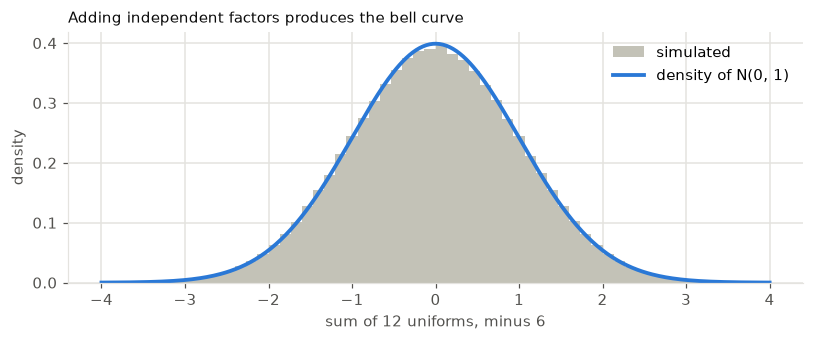

In [2]:
S = rng.uniform(0, 1, size=(1_000_000, 12)).sum(axis=1) - 6
print(f"mean {S.mean():.4f} (exact 0), variance {S.var():.4f} (exact 1)")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
hist_vs_density(ax, S, normal_pdf, -4, 4, "density of N(0, 1)")
ax.set(xlabel="sum of 12 uniforms, minus 6", ylabel="density")
ax.legend(frameon=False)
ax.set_title("Adding independent factors produces the bell curve", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Observations (slide 3)

All of these can be read directly from the formula:

- **Symmetric around $\mu$.** The density depends on $x$ only through $(x - \mu)^2$.
- **Mode at $\mu$.** The exponent is largest (zero) at $x = \mu$, so the peak height is $f(\mu) = \frac{1}{\sqrt{2\pi\sigma^2}}$.
- **Larger $\sigma$ flattens the curve.** The peak height is proportional to $1/\sigma$, and the area must stay 1, so the curve must spread out.

**Where the curve bends.** The slides mark $\mu \pm \sigma$ on the curve, and these are the inflection points. Differentiating twice,

$$f'(x) = -\frac{x - \mu}{\sigma^2} f(x), \qquad f''(x) = \left(\frac{(x - \mu)^2}{\sigma^4} - \frac{1}{\sigma^2}\right) f(x).$$

So $f'' = 0$ exactly when $x = \mu \pm \sigma$. The curve is concave between those two points and convex outside them, which Session 2 will use.

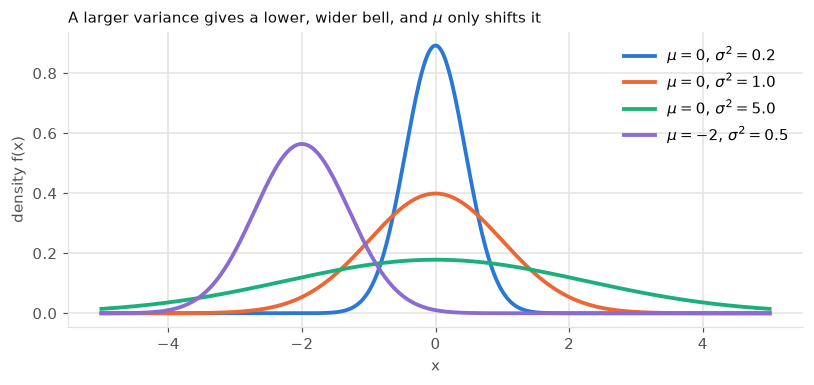

In [3]:
xs = np.linspace(-5, 5, 1001)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for mu, var, color in [(0, 0.2, BLUE), (0, 1.0, ORANGE), (0, 5.0, AQUA), (-2, 0.5, PURPLE)]:
    ax.plot(xs, normal_pdf(xs, mu, var), color=color, lw=2.5, label=f"$\\mu = {mu}$, $\\sigma^2 = {var}$")
ax.set(xlabel="x", ylabel="density f(x)")
ax.legend(frameon=False)
ax.set_title("A larger variance gives a lower, wider bell, and $\\mu$ only shifts it", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
print(" mu  var   grid argmax   peak on grid   1/sqrt(2 pi var)")
xs = np.linspace(-6, 6, 120_001)
for mu, var in [(0, 0.2), (0, 1), (0, 5), (-2, 0.5)]:
    f = normal_pdf(xs, mu, var)
    print(f"{mu:3} {var:4}     {xs[f.argmax()]:7.3f}       {f.max():.5f}        {1 / sqrt(2 * pi * var):.5f}")

mu, var, h = 3, 4, 1e-4
sigma = sqrt(var)
second = lambda x: (normal_pdf(x + h, mu, var) - 2 * normal_pdf(x, mu, var) + normal_pdf(x - h, mu, var)) / h ** 2
print(f"\nf'' for mu = {mu}, sigma = {sigma:.0f}, at mu - sigma: {second(mu - sigma):.6f}, at mu + sigma: {second(mu + sigma):.6f}")

 mu  var   grid argmax   peak on grid   1/sqrt(2 pi var)
  0  0.2       0.000       0.89206        0.89206
  0    1       0.000       0.39894        0.39894
  0    5       0.000       0.17841        0.17841
 -2  0.5      -2.000       0.56419        0.56419

f'' for mu = 3, sigma = 2, at mu - sigma: 0.000000, at mu + sigma: 0.000000


## 4. Linear transformations (slide 4)

**Claim.** Linear transformations of normal distributions are normal:

$$X \sim N(\mu, \sigma^2) \quad \Longrightarrow \quad aX + b \sim N\big(a\mu + b,\, (a\sigma)^2\big), \qquad a \ne 0.$$

**Consistency check.** For $Y = aX + b$, linearity of expectation (LoE) always gives $\mu_Y = a\mu_X + b$, and the quadratic rule for variance (QV) always gives $\sigma_Y^2 = a^2 \sigma_X^2$. So those parameters are the only ones that could work. What is new is that the *shape* stays normal.

**Proof.** Use the variable transformation for $Y = g(X)$,

$$f_Y(y) = \frac{1}{\lvert g'(x) \rvert} f_X(x) \Big|_{y = g(x)},$$

with $g(x) = ax + b$, so that $\lvert g' \rvert = \lvert a \rvert$ and $x = \frac{y - b}{a}$. Then

$$f_Y(y) = \frac{1}{\lvert a \rvert} \cdot \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-\frac{\left(\frac{y - b}{a} - \mu\right)^2}{2\sigma^2}} = \frac{1}{\sqrt{2\pi(a\sigma)^2}}\, e^{-\frac{(y - (a\mu + b))^2}{2(a\sigma)^2}}.$$

The second step moves $\lvert a \rvert$ under the root, and multiplies the top and bottom of the exponent by $a^2$. This is the density of $N\big(a\mu + b, (a\sigma)^2\big)$.

For negative $a$, note that $\sqrt{(a\sigma)^2} = \lvert a \rvert \sigma$. The standard deviation is $\lvert a \rvert \sigma$, not $a\sigma$.

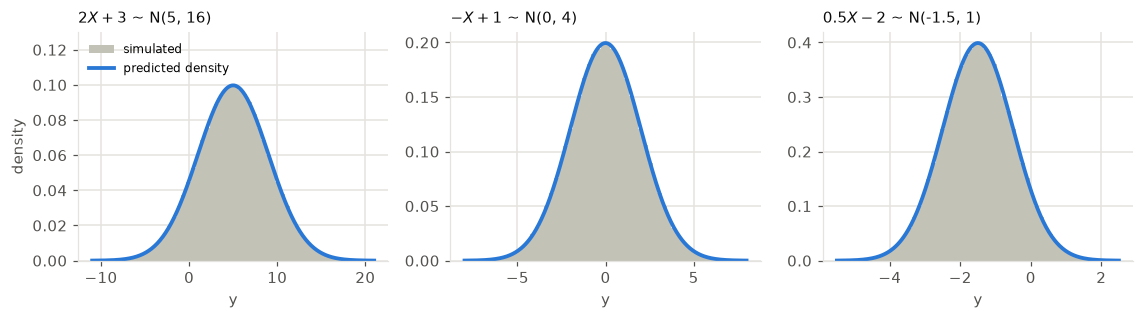

In [5]:
X = rng.normal(1, 2, size=1_000_000)
maps = [("$2X + 3$", 2, 3), ("$-X + 1$", -1, 1), ("$0.5X - 2$", 0.5, -2)]

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
for ax, (name, a, b) in zip(axes, maps):
    mu_y, var_y = a * 1 + b, (a * 2) ** 2
    lo, hi = mu_y - 4 * sqrt(var_y), mu_y + 4 * sqrt(var_y)
    hist_vs_density(ax, a * X + b, lambda y, m=mu_y, v=var_y: normal_pdf(y, m, v), lo, hi, "predicted density")
    ax.set_title(f"{name} ~ N({mu_y:g}, {var_y:g})", color=INK, loc="left", fontsize=10)
    ax.set(xlabel="y")
axes[0].set_ylabel("density")
axes[0].set_ylim(0, 0.13)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 5. One standard normal (slides 5-6)

Since $aX + b$ is normal with mean parameter $a\mu + b$ and variance parameter $a^2\sigma^2$, every normal comes from one **standard** normal $X^* \sim N(0, 1)$:

$$X = \sigma X^* + \mu \sim N(\sigma \cdot 0 + \mu,\, \sigma^2 \cdot 1) = N(\mu, \sigma^2).$$

This is the same plan that gave us the moments of $U_{[a,b]}$ from those of $U_{[0,1]}$. So it remains to study this one distribution.

It has a standard name too. Slide 6 is a joke collage of brands that start with Z, because this variable is always called $Z$.

## 6. What must be shown (slides 7-8)

**The $Z$ distribution.** Setting $\mu = 0$, $\sigma^2 = 1$, and $x \to z$ in the general formula,

$$Z \sim N(0, 1), \qquad f_Z(z) = \frac{1}{\sqrt{2\pi}}\, e^{-z^2/2} \triangleq \phi(z).$$

**To show, for $N(0, 1)$:** that $\int_{-\infty}^{\infty} f_Z(z)\, dz = 1$, that $E[Z] = 0$, and that $V(Z) = 1$. Then 0 and 1 really are the mean and the variance.

**Why the stakes are high.** We have shown that $X \triangleq \sigma Z + \mu$ has the density of $N(\mu, \sigma^2)$. So each fact about $Z$ implies the same fact for every normal:

| If we show, for $Z$ | Then, for $X = \sigma Z + \mu$ | Meaning |
|---|---|---|
| $\int f_Z(z)\, dz = 1$ | $Z$ is a random variable, so $X$ is too, and $\int f_X(x)\, dx = 1$ | $f_X$ is a valid density |
| $E[Z] = 0$ | $E[X] = \sigma E[Z] + \mu = \mu$ | $\mu$ is the mean |
| $V(Z) = 1$ | $V(X) = \sigma^2 V(Z) = \sigma^2$ | $\sigma^2$ is the variance |

There is no circularity, since Section 4 used only a change of variables, and no moments of $X$.

## 7. Does it integrate to 1? (slides 9-11)

Pull out the constant:

$$\int_{-\infty}^{\infty} f_Z(z)\, dz = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{\infty} e^{-z^2/2}\, dz.$$

The function $e^{-z^2/2}$ has no elementary antiderivative, so a direct attack fails. The classic trick is to **square** the integral. Let

$$I \triangleq \int_{-\infty}^{\infty} e^{-z^2/2}\, dz.$$

Write $I^2$ as a product of two copies with different dummy variables, and combine them into a double integral:

$$I^2 = \left(\int_{-\infty}^{\infty} e^{-x^2/2}\, dx\right)\left(\int_{-\infty}^{\infty} e^{-y^2/2}\, dy\right) = \int_{-\infty}^{\infty}\int_{-\infty}^{\infty} e^{-(x^2 + y^2)/2}\, dx\, dy.$$

The exponent depends only on the distance from the origin, so switch to polar coordinates: $x = r\cos\theta$, $y = r\sin\theta$, $x^2 + y^2 = r^2$. A small polar patch has sides $\Delta r$ and $r\Delta\theta$, so its area is about $r\, \Delta r\, \Delta\theta$, that is, $dx\, dy = r\, dr\, d\theta$. Then

$$I^2 = \int_0^\infty \int_0^{2\pi} e^{-r^2/2}\, r\, d\theta\, dr = 2\pi \int_0^\infty r e^{-r^2/2}\, dr.$$

The extra factor $r$ is what makes the integral easy, since $\int r e^{-r^2/2}\, dr = -e^{-r^2/2}$:

$$I^2 = 2\pi \left(-e^{-r^2/2}\right) \Big|_0^\infty = 2\pi, \qquad \text{so} \qquad I = \sqrt{2\pi}.$$

The constant in the density is exactly what is needed:

$$\int_{-\infty}^{\infty} f_Z(z)\, dz = \frac{1}{\sqrt{2\pi}} \cdot \sqrt{2\pi} = 1.$$

In [6]:
I, _ = quad(lambda z: exp(-z ** 2 / 2), -np.inf, np.inf)
print(f"I = {I:.8f}, sqrt(2 pi) = {sqrt(2 * pi):.8f}")

# The double integral on a grid, and the radial integral after the polar change.
grid = np.linspace(-8, 8, 2001)
dx = grid[1] - grid[0]
x, y = np.meshgrid(grid, grid)
print(f"I^2 on a grid: {np.exp(-(x ** 2 + y ** 2) / 2).sum() * dx ** 2:.6f}, 2 pi = {2 * pi:.6f}")
radial, _ = quad(lambda r: r * exp(-r ** 2 / 2), 0, np.inf)
print(f"radial integral: {radial:.6f}, so I^2 = 2 pi x {radial:.3f}")

for mu, var in [(0, 1), (15, 4), (-3, 0.25)]:
    area, _ = quad(lambda t: normal_pdf(t, mu, var), mu - 12 * sqrt(var), mu + 12 * sqrt(var))
    print(f"N({mu}, {var}): area = {area:.8f}")

I = 2.50662827, sqrt(2 pi) = 2.50662827
I^2 on a grid: 6.283185, 2 pi = 6.283185
radial integral: 1.000000, so I^2 = 2 pi x 1.000
N(0, 1): area = 1.00000000
N(15, 4): area = 1.00000000
N(-3, 0.25): area = 1.00000000


## 8. Expectation (slide 12)

There are two routes to $E[Z] = 0$.

**By symmetry (the easy way).** $\phi$ is symmetric around 0, and the integral converges, so the mean is the center, 0.

**By direct calculation.** Use $\int z e^{-z^2/2}\, dz = -e^{-z^2/2}$:

$$E[Z] = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{\infty} z e^{-z^2/2}\, dz = \frac{1}{\sqrt{2\pi}} \left[-e^{-z^2/2}\right]_{-\infty}^{\infty} = 0 - 0 = 0.$$

(The slide has a stray $dz$ inside the bracket on this line.)

## 9. Variance (slide 13)

Since $E[Z] = 0$, the variance is just $E[Z^2]$. Integrate by parts with $u = z$ and $dv = z e^{-z^2/2}\, dz$, so that $du = dz$ and $v = -e^{-z^2/2}$:

$$E[Z^2] = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{\infty} z^2 e^{-z^2/2}\, dz = \frac{-1}{\sqrt{2\pi}} z e^{-z^2/2} \Big|_{-\infty}^{\infty} + \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{\infty} e^{-z^2/2}\, dz = 0 + 1 = 1.$$

The boundary term vanishes because the exponential beats $z$, and the remaining integral is the normalization from Section 7. Therefore

$$V(Z) = E[Z^2] - (E[Z])^2 = 1 - 0 = 1.$$

(The slide writes this calculation with the letter $X$, but it is about the standard normal.)

In [7]:
m1, _ = quad(lambda z: z * normal_pdf(z), -np.inf, np.inf)
m2, _ = quad(lambda z: z ** 2 * normal_pdf(z), -np.inf, np.inf)
Z = rng.standard_normal(2_000_000)
print(f"E[Z]:   numeric {m1:.6f}, simulated {Z.mean():.4f}")
print(f"E[Z^2]: numeric {m2:.6f}, simulated {(Z ** 2).mean():.4f}")
print(f"V(Z):   numeric {m2 - m1 ** 2:.6f}, simulated {Z.var():.4f}")

E[Z]:   numeric 0.000000, simulated 0.0001
E[Z^2]: numeric 1.000000, simulated 0.9996
V(Z):   numeric 1.000000, simulated 0.9996


## 10. The payback (slide 14)

Mission accomplished. For the standard normal $Z \sim N(0, 1)$, we have $\mu = 0$ and $V = 1$. For the general normal $X \sim N(\mu, \sigma^2)$, write $X = \sigma Z + \mu$, and then

$$E[X] = \sigma E[Z] + \mu = \mu, \qquad V(X) = \sigma^2 V(Z) = \sigma^2.$$

So the parameter names were deserved. The slide asks whether this comes with a reward. Perhaps not riches, but at least you can answer "of course I know the normal" in an interview, and you can use it at work, where data such as stock returns are often compared to a bell curve.

In [8]:
print("  mu  sigma   E[X] numeric   V(X) numeric   sigma^2")
for mu, sigma in [(0, 1), (15, 2), (-3, 0.5), (100, 15)]:
    lo, hi = mu - 12 * sigma, mu + 12 * sigma
    m, _ = quad(lambda t: t * normal_pdf(t, mu, sigma ** 2), lo, hi)
    s, _ = quad(lambda t: (t - m) ** 2 * normal_pdf(t, mu, sigma ** 2), lo, hi)
    print(f"{mu:4} {sigma:6}   {m:10.5f}   {s:12.5f}   {sigma ** 2:7.2f}")

  mu  sigma   E[X] numeric   V(X) numeric   sigma^2
   0      1      0.00000        1.00000      1.00
  15      2     15.00000        4.00000      4.00
  -3    0.5     -3.00000        0.25000      0.25
 100     15    100.00000      225.00000    225.00


## 11. Quiz: a normal modification (slide 15)

**Question.** Affine modifications of a normal are normal. Are they the only maps that send a normal to a normal?

**Answer: no.** Let $Z \sim N_{0,1}$, and flip the sign outside $[-1, 1]$:

$$X = \begin{cases} Z & \text{if } \lvert Z \rvert < 1 \\ -Z & \text{if } \lvert Z \rvert \ge 1. \end{cases}$$

| $Z$ | $X$ |
|---|---|
| $0.5$ | $0.5$ |
| $-0.5$ | $-0.5$ |
| $2$ | $-2$ |
| $-2$ | $2$ |

**Density.** The map is its own inverse, with slope of absolute value 1 on each piece. So

$$f_X(x) = \begin{cases} f_Z(x) & \text{if } \lvert x \rvert < 1 \\ f_Z(-x) & \text{if } \lvert x \rvert \ge 1 \end{cases} = f_Z(x),$$

where the last step uses the symmetry of $f_Z$. Hence $X \sim N_{0,1}$, even though $X$ is not an affine function of $Z$.

**A warning for later.** $X$ and $Z$ are both standard normal, yet their sum is not normal. $X + Z = 2Z$ when $\lvert Z \rvert < 1$, and $X + Z = 0$ otherwise, so the sum equals 0 with probability $P(\lvert Z \rvert \ge 1) \approx 0.32$. A continuous distribution cannot do that. This pair returns when we reach bivariate normals.

    q     quantile of X   quantile of N(0,1)
 0.01       -2.3271        -2.3263
  0.1       -1.2815        -1.2816
 0.25       -0.6739        -0.6745


  0.5       -0.0000         0.0000
 0.75        0.6748         0.6745
  0.9        1.2817         1.2816
 0.99        2.3261         2.3263

P(X = Z): simulated 0.6825, exact P(|Z| < 1) = 0.6827
P(X + Z = 0): simulated 0.3175, exact P(|Z| >= 1) = 0.3173


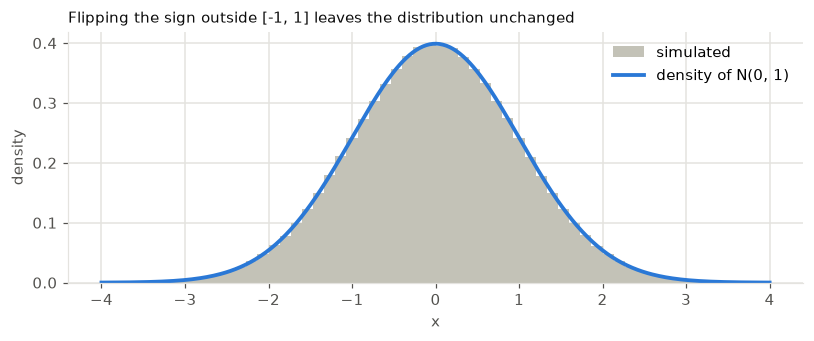

In [9]:
Z = rng.standard_normal(2_000_000)
X = np.where(np.abs(Z) < 1, Z, -Z)

print("    q     quantile of X   quantile of N(0,1)")
for q in [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]:
    print(f"{q:5}     {np.quantile(X, q):9.4f}      {norm.ppf(q):9.4f}")

S = X + Z
print(f"\nP(X = Z): simulated {np.mean(X == Z):.4f}, exact P(|Z| < 1) = {norm.cdf(1) - norm.cdf(-1):.4f}")
print(f"P(X + Z = 0): simulated {np.mean(S == 0):.4f}, exact P(|Z| >= 1) = {2 * norm.sf(1):.4f}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
hist_vs_density(ax, X, normal_pdf, -4, 4, "density of N(0, 1)")
ax.set(xlabel="x", ylabel="density")
ax.legend(frameon=False)
ax.set_title("Flipping the sign outside [-1, 1] leaves the distribution unchanged", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 12. Summary (slide 16)

| Item | Result |
|---|---|
| Family | $N(\mu, \sigma^2)$ with density $\frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-(x - \mu)^2/(2\sigma^2)}$, for $-\infty < x < \infty$ |
| Parameters | $\mu$ is the mean and $\sigma^2$ is the variance |
| Standard normal | $Z \sim N(0, 1)$ with density $\phi(z) = \frac{1}{\sqrt{2\pi}}\, e^{-z^2/2}$ |
| Where it appears | Sums of many independent variables, hence height, weight, income, and so on |
| Closure | Affine maps $aX + b$ of a normal are normal |

The slide prints the exponent of $\phi(z)$ with $x^2$ in place of $z^2$, which is a typo.

## Common pitfalls

1. **Reading the second parameter as $\sigma$.** $N(15, 4)$ has variance 4 and standard deviation 2. Check whether a source writes the variance or the standard deviation.
2. **Writing $\sigma_Y = a\sigma$ for negative $a$.** The standard deviation of $aX + b$ is $\lvert a \rvert \sigma$.
3. **Treating the density as a probability.** $N(0, 0.01)$ has peak height about $3.99$, and $P(X = \mu) = 0$, whatever $f(\mu)$ is.
4. **Forgetting that the constant depends on $\sigma$.** Halving $\sigma$ doubles the peak.
5. **Confusing $X + X$ with a sum of independent copies.** If $X \sim N(0, 1)$, then $X + X = 2X \sim N(0, 4)$, not $N(0, 2)$.
6. **Dropping the $r$ in polar coordinates.** $dx\, dy = r\, dr\, d\theta$, and the factor $r$ is what makes the integral solvable.
7. **Assuming the Gaussian integral works on any interval.** The squaring trick evaluates the integral over the whole line. Partial integrals need the table or a program, which is the topic of Session 2.
8. **Concluding that normal marginals make a normal sum.** The quiz gives two standard normals whose sum is not normal.

## Key takeaways

- **Density:** $f(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-(x - \mu)^2/(2\sigma^2)}$, symmetric around $\mu$, with its mode at $\mu$, peak height $\frac{1}{\sqrt{2\pi\sigma^2}}$, and inflection points at $\mu \pm \sigma$.
- **Closure:** $aX + b \sim N(a\mu + b, a^2\sigma^2)$, by the change-of-variables formula.
- **Reduction:** every normal is $X = \sigma Z + \mu$, so everything needs proving only for $Z \sim N(0, 1)$.
- **Gaussian integral:** square it, switch to polar coordinates, and get $\int_{-\infty}^{\infty} e^{-z^2/2}\, dz = \sqrt{2\pi}$.
- **Moments:** $E[Z] = 0$ by symmetry, and $V(Z) = 1$ by parts, so $E[X] = \mu$ and $V(X) = \sigma^2$.
- **Quiz:** flipping the sign of $Z$ outside $[-1, 1]$ keeps it standard normal, so affine maps are not the only normal-to-normal maps.
- Next: Session 2 computes normal probabilities, with the Z table, standardization, and the 68-95-99.7 rule.